<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" width="240" alt="Query.Farm"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" width="150" alt="VGI"></a>

# How does a larger recommendation slate change exposure?

We will fit implicit-feedback ALS through the real recommendation worker on a small **authored learning-module interaction matrix**. Then we will audit novel-item recommendations, compare the single-user and all-user APIs, and inspect item similarities. Finally, we will ask for one more recommendation per learner while holding model settings fixed.

The learners and counts are synthetic. A count records interaction strength, not a rating; a missing interaction is unknown, not dislike. Scores are latent-factor affinities, not probabilities or evidence of recommendation accuracy. This is a behavior audit, not a held-out evaluation. [Setup and pinned runtime](README.md).

## Choose the slate size

`SLATE_SIZE` is an integer **1–4**: the maximum number of novel items per learner. Default **2**; experiment **3**. A learner can receive fewer when no novel candidates remain. The model uses **3 latent factors**, 30 sweeps, regularization 0.01, seed 42 and one numerical thread. The 8×8 input is large enough that the worker does not clamp the factor count. Restart and run all after editing.

In [1]:
SLATE_SIZE = 2  # Maximum novel recommendations per learner; experiment: 3.

In [2]:
import haybarn
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from IPython.display import display

from notebook_support import chart, cleanup, configure, prose, theme

previous = configure(SLATE_SIZE)
theme()
connection = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.displaylimit = 20
%sql connection

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/lane-2/vgi-recommender/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/lane-2/vgi-recommender/notebooks/pyproject.toml.

## Attach the tagged release

The visible public Git command pins worker release v0.4.0 and its SDK and numerical dependencies. The worker fits ALS; Python in this notebook only configures threads and presents SQL results. The first run needs internet for the published packages, Git revision and extension. No checkout source or local worker environment is discovered.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'recommender' (TYPE vgi,
    LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-recommender@v0.4.0 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --with pyarrow==26.0.1 --with implicit==0.7.3 --with numpy==2.5.4 --with scipy==1.18.1 --with pandas==3.1.1 vgi-recommender');
CREATE TABLE settings AS SELECT {{ SLATE_SIZE }}::INTEGER AS slate_size;

Running query in 'DuckDBPyConnection'

1 rows affected.

,Count


## Keep the interaction matrix visible

Eight fictional learners interact with eight modules. Several share SQL or analysis modules; a smaller pair concerns deployment/logging. Learner L08 has interacted with **every** module and should receive no novel recommendation. Counts are positive integers. The authored pattern is deliberately small and structured, so it is not a representative learning dataset. Module titles are display labels, not model inputs.

In [4]:
%%sql
CREATE TABLE modules(item,title) AS VALUES
('A','SQL basics'),('B','Joins'),('C','Window functions'),('D','Plotting'),
('E','Statistics'),('F','Models'),('G','Deployment'),('H','Logging');
CREATE TABLE events(learner,item,interactions) AS VALUES
('L01','A',3),('L01','B',3),('L01','C',3),
('L02','A',1),('L02','B',1),('L02','C',1),
('L03','A',2),('L03','B',2),
('L04','D',3),('L04','E',3),('L04','F',3),
('L05','D',1),('L05','E',1),('L05','F',1),
('L06','D',2),('L06','E',2),
('L07','G',2),('L07','H',2),
('L08','A',1),('L08','B',1),('L08','C',1),('L08','D',1),
('L08','E',1),('L08','F',1),('L08','G',1),('L08','H',1);
CREATE TABLE learners AS SELECT DISTINCT learner FROM events;
SELECT learner,count(*) AS observed_modules,sum(interactions) AS total_interactions
FROM events GROUP BY learner ORDER BY learner;

Running query in 'DuckDBPyConnection'

8 rows affected.

26 rows affected.

8 rows affected.

,learner,observed_modules,total_interactions
0,L01,3,9.0
1,L02,3,3.0
2,L03,2,4.0
3,L04,3,9.0
4,L05,3,3.0
5,L06,2,4.0
6,L07,2,4.0
7,L08,8,8.0


## Fit and materialize recommendations before inspecting them

Each function consumes the **whole relation** and fits its own deterministic model. We materialize once per call before any DataFrame capture so chart display cannot trigger a second training run. `recommend_all` returns item IDs, rank and score; `recommend_for` repeats the same configuration for L03 as an API consistency check. A request for an unknown learner is evaluated separately and should emit zero rows, not an invented default list.

In [5]:
%%sql
CREATE TABLE recommendations AS
SELECT * FROM recommender.main.recommend_all((SELECT learner,item,interactions FROM events ORDER BY learner,item),
    user:='learner',item:='item',value:='interactions',n:={{ SLATE_SIZE }},factors:=3);
CREATE TABLE one_learner AS
SELECT * FROM recommender.main.recommend_for((SELECT learner,item,interactions FROM events ORDER BY learner,item),
    user:='learner',item:='item',value:='interactions',target_user:='L03',n:={{ SLATE_SIZE }},factors:=3);
CREATE TABLE unknown_learner AS
SELECT * FROM recommender.main.recommend_for((SELECT learner,item,interactions FROM events ORDER BY learner,item),
    user:='learner',item:='item',value:='interactions',target_user:='NEW',n:={{ SLATE_SIZE }},factors:=3);
SELECT r.user AS learner,r.rank,m.title,round(r.score,5) AS affinity_score
FROM recommendations r JOIN modules m USING(item) ORDER BY learner,rank;

Running query in 'DuckDBPyConnection'

14 rows affected.

2 rows affected.

,learner,rank,title,affinity_score
0,L01,1,Models,0.02378
1,L01,2,Deployment,0.02019
2,L02,1,Models,0.02093
3,L02,2,Deployment,0.00726
4,L03,1,Window functions,0.69884
5,L03,2,Models,0.00850
6,L04,1,Window functions,0.02309
7,L04,2,Logging,0.01956
8,L05,1,Window functions,0.02012
9,L05,2,Logging,0.00666


In [6]:
%%sql summary_frame <<
SELECT l.learner,count(r.item) AS returned,
       (SELECT count(*) FROM modules)-(SELECT count(*) FROM events e WHERE e.learner=l.learner) AS novel_candidates,
       CASE WHEN count(r.item)=0 THEN 'No novel candidates' ELSE 'Recommendations returned' END AS availability
FROM learners l LEFT JOIN recommendations r ON r.user=l.learner
GROUP BY l.learner ORDER BY l.learner;

Running query in 'DuckDBPyConnection'

In [7]:
display(summary_frame)
prose(
    f"The worker returns **{int(summary_frame.returned.sum())} recommendations** across "
    f"**{int((summary_frame.returned > 0).sum())} learners** at maximum slate size **{SLATE_SIZE}**. "
    "L08 stays in the availability table with zero returned rows because all modules were seen. "
    "The unknown learner NEW is checked separately below. Zero recommendations are not missing scores "
    "and do not imply that a known learner dislikes every remaining item."
)

,learner,returned,novel_candidates,availability
0,L01,2,5,Recommendations returned
1,L02,2,5,Recommendations returned
2,L03,2,6,Recommendations returned
3,L04,2,5,Recommendations returned
4,L05,2,5,Recommendations returned
5,L06,2,6,Recommendations returned
6,L07,2,6,Recommendations returned
7,L08,0,0,No novel candidates


The worker returns **14 recommendations** across **7 learners** at maximum slate size **2**. L08 stays in the availability table with zero returned rows because all modules were seen. The unknown learner NEW is checked separately below. Zero recommendations are not missing scores and do not imply that a known learner dislikes every remaining item.

## Read observed interactions beside returned ranks

The left panel shows authored interaction counts, with blank cells for no recorded interaction. The right shows worker recommendation ranks, with **1 best**. A gray × marks a previously seen module; blank cells are novel but not selected. These panels use different color scales: count and ordinal rank. The rank scale stays fixed at 1–4 across slate-size experiments. They do not turn unobserved interactions into negative labels.

In [8]:
%%sql matrix_frame <<
SELECT l.learner,m.item,m.title,e.interactions,r.rank
FROM learners l CROSS JOIN modules m LEFT JOIN events e ON e.learner=l.learner AND e.item=m.item
LEFT JOIN recommendations r ON r.user=l.learner AND r.item=m.item
ORDER BY l.learner,m.item;

Running query in 'DuckDBPyConnection'

findfont: Failed to find font weight semibold for Arial, now using 700.


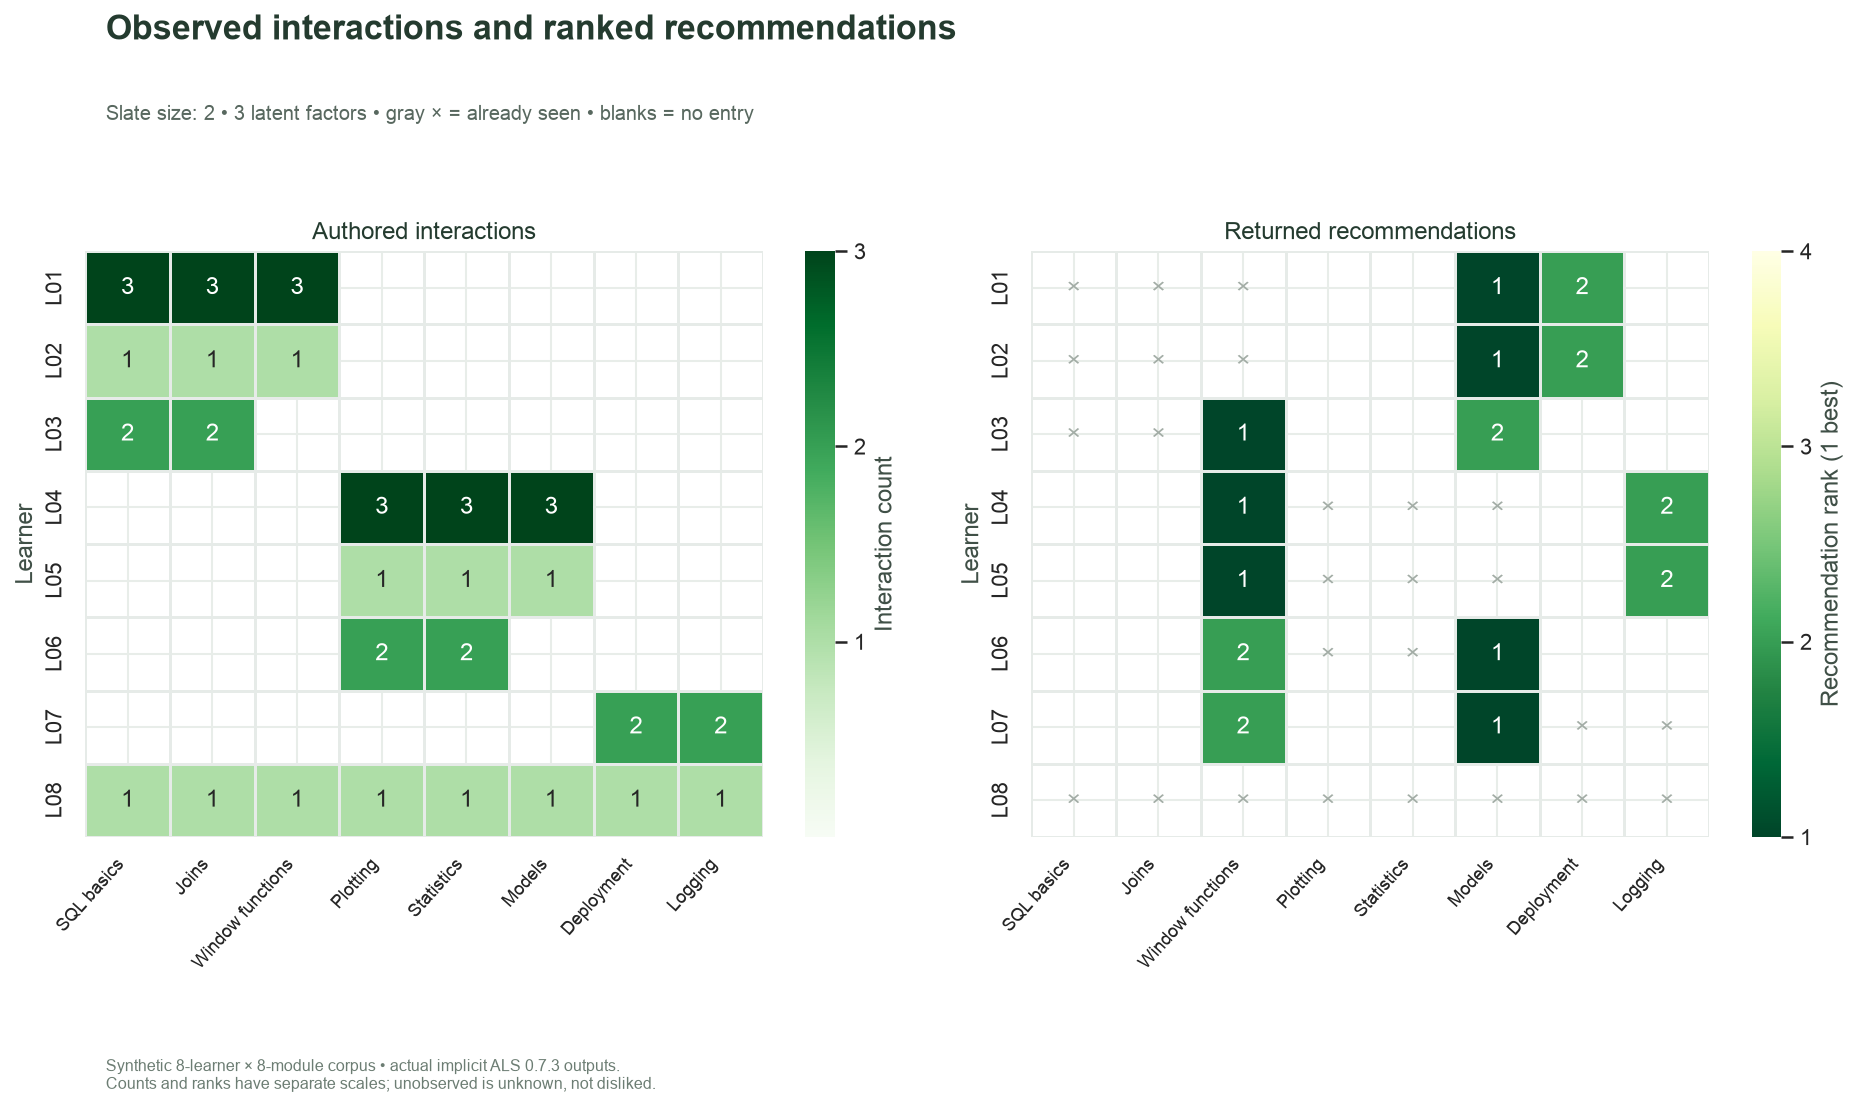

In [9]:
observed = matrix_frame.pivot(index="learner", columns="item", values="interactions").astype(float)
ranks = matrix_frame.pivot(index="learner", columns="item", values="rank").astype(float)
titles = matrix_frame.drop_duplicates("item").sort_values("item").title.tolist()
fig, axes = plt.subplots(1, 2, figsize=(13.5, 7.8))
sns.heatmap(
    observed,
    mask=observed.isna(),
    annot=True,
    fmt=".0f",
    cmap="Greens",
    vmin=0,
    vmax=3,
    linewidths=0.7,
    linecolor="#E6EBE8",
    cbar_kws={"label": "Interaction count", "ticks": [1, 2, 3]},
    ax=axes[0],
)
sns.heatmap(
    ranks,
    mask=ranks.isna(),
    annot=True,
    fmt=".0f",
    cmap="YlGn_r",
    vmin=1,
    vmax=4,
    linewidths=0.7,
    linecolor="#E6EBE8",
    cbar_kws={"label": "Recommendation rank (1 best)", "ticks": [1, 2, 3, 4]},
    ax=axes[1],
)
for y, x in zip(*np.where(observed.notna()), strict=True):
    axes[1].text(x + 0.5, y + 0.5, "×", ha="center", va="center", color="#A3ADA6", fontsize=13)
for ax, title in zip(axes, ["Authored interactions", "Returned recommendations"], strict=True):
    ax.set(title=title, xlabel="", ylabel="Learner")
    ax.set_xticklabels(titles, rotation=48, ha="right", fontsize=9)
chart(
    fig,
    "Observed interactions and ranked recommendations",
    f"Slate size: {SLATE_SIZE} • 3 latent factors • gray × = already seen • blanks = no entry",
    "Synthetic 8-learner × 8-module corpus • actual implicit ALS 0.7.3 outputs.\n"
    "Counts and ranks have separate scales; unobserved is unknown, not disliked.",
)

## Count item exposure and inspect model neighbors

Count how often each module appears across returned slates, including zero-exposure modules. These counts describe the proposed lists, not actual clicks or learning outcomes. The similarity query uses the same input and model settings but asks a different question: cosine similarity between item factors. It is not a probability and should not be compared numerically with user recommendation scores.

In [10]:
%%sql
CREATE TABLE exposure AS
SELECT m.item,m.title,count(r.user) AS appearances FROM modules m
LEFT JOIN recommendations r USING(item) GROUP BY m.item,m.title;
CREATE TABLE neighbors AS
SELECT * FROM recommender.main.similar_items((SELECT learner,item,interactions FROM events ORDER BY learner,item),
    user:='learner',item:='item',value:='interactions',n:=3,factors:=3);
SELECT n.item,m.title AS neighbor,n.rank,round(n.similarity,5) AS cosine_similarity
FROM neighbors n JOIN modules m ON m.item=n.similar_item
WHERE n.item='C' ORDER BY n.rank;

Running query in 'DuckDBPyConnection'

8 rows affected.

24 rows affected.

,item,neighbor,rank,cosine_similarity
0,C,Joins,1,0.99534
1,C,SQL basics,2,0.99534
2,C,Deployment,3,-0.08672


In [11]:
%%sql exposure_frame <<
SELECT * FROM exposure ORDER BY item;

Running query in 'DuckDBPyConnection'

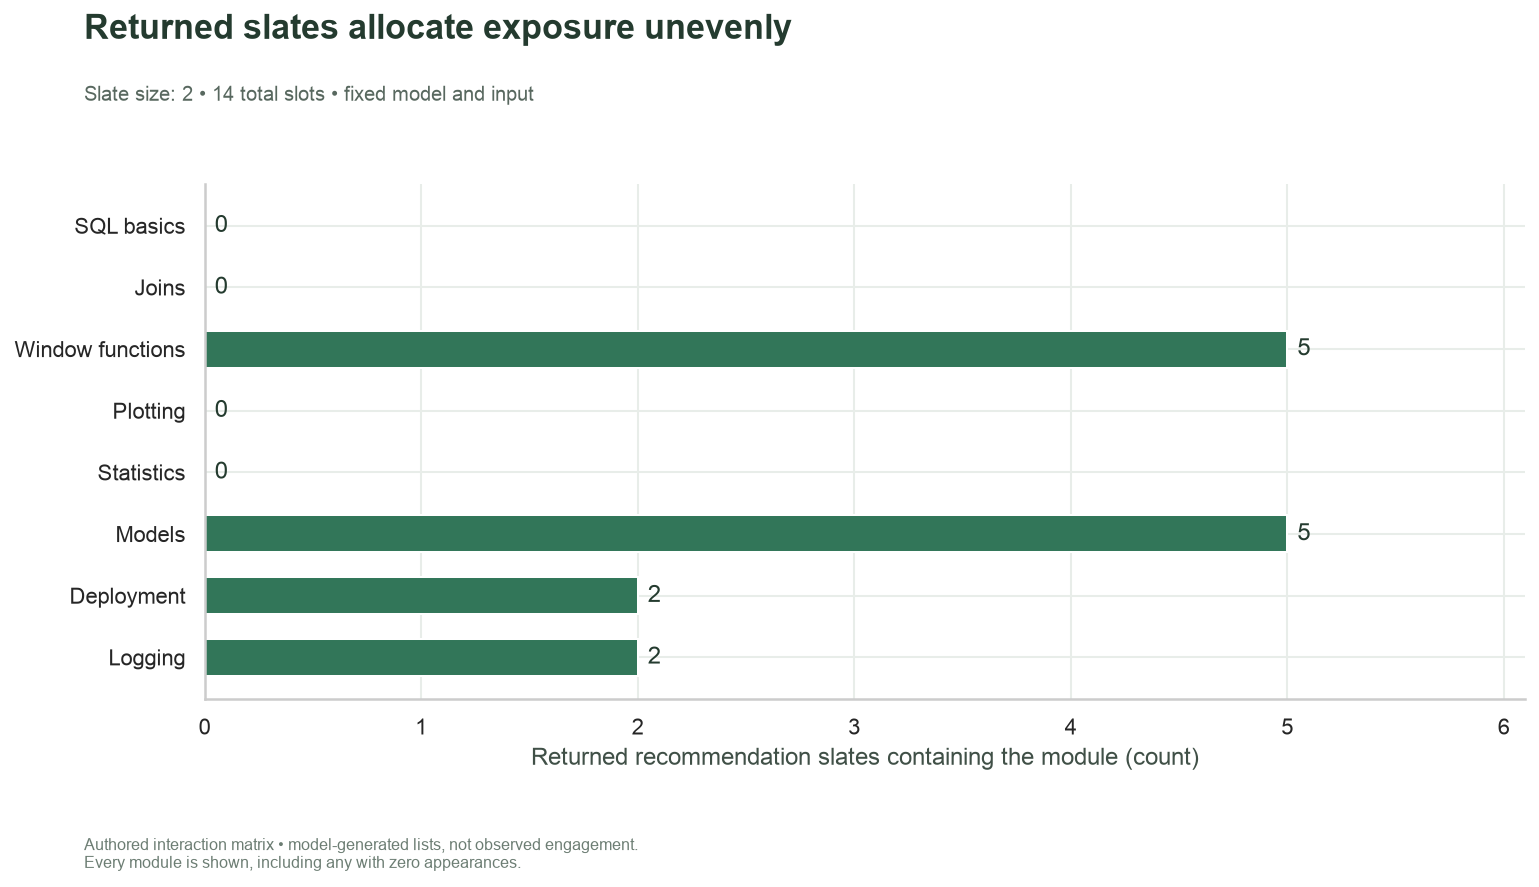

In [12]:
fig, ax = plt.subplots(figsize=(11, 6.2))
bars = ax.barh(exposure_frame.title, exposure_frame.appearances, color="#327659", height=0.6)
ax.bar_label(bars, padding=5)
ax.invert_yaxis()
ax.set(
    xlabel="Returned recommendation slates containing the module (count)",
    xlim=(0, max(1, exposure_frame.appearances.max()) + 1.1),
)
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
chart(
    fig,
    "Returned slates allocate exposure unevenly",
    f"Slate size: {SLATE_SIZE} • {int(exposure_frame.appearances.sum())} total slots • fixed model and input",
    "Authored interaction matrix • model-generated lists, not observed engagement.\n"
    "Every module is shown, including any with zero appearances.",
)

## Audit novelty, cardinality and API agreement

The checks verify unique learner/item pairs, contiguous ranks, finite scores, the slate-size cap and exclusion of already-seen items. The single-learner API must agree with its rows in the all-learner result at the same settings. Unknown learners and the fully observed learner have distinct reasons for returning no rows. Item-neighbor identities must be unique and exclude self-matches; cosine bounds allow a small floating-point tolerance. None of these checks measures predictive accuracy.

In [13]:
%%sql
CREATE TABLE checks AS
SELECT 'Input interactions are positive and unique' AS check_name,bool_and(interactions>0) AND count(*)=count(DISTINCT (learner,item)) AS passed FROM events
UNION ALL SELECT 'Recommendation pairs are unique',count(*)=count(DISTINCT (user,item)) FROM recommendations
UNION ALL SELECT 'No already-seen item is recommended',count(*)=0 FROM recommendations r JOIN events e ON e.learner=r.user AND e.item=r.item
UNION ALL SELECT 'Every recommended identity is known',count(*)=0 FROM recommendations r LEFT JOIN learners l ON l.learner=r.user LEFT JOIN modules m ON m.item=r.item WHERE l.learner IS NULL OR m.item IS NULL
UNION ALL SELECT 'All returned scores are finite',bool_and(isfinite(score)) FROM recommendations
UNION ALL SELECT 'Ranks are contiguous and respect slate size',bool_and(first_rank=1 AND last_rank=rows AND rows<=slate_size) FROM (SELECT user,min(rank) AS first_rank,max(rank) AS last_rank,count(*) AS rows FROM recommendations GROUP BY user) CROSS JOIN settings
UNION ALL SELECT 'Available candidates explain slate lengths',bool_and(returned=least(novel_candidates,slate_size)) FROM (SELECT l.learner,count(r.item) AS returned,(SELECT count(*) FROM modules)-(SELECT count(*) FROM events e WHERE e.learner=l.learner) AS novel_candidates FROM learners l LEFT JOIN recommendations r ON r.user=l.learner GROUP BY l.learner) CROSS JOIN settings
UNION ALL SELECT 'Single-user identities and ranks agree',count(*)=0 FROM ((SELECT item,rank FROM one_learner EXCEPT SELECT item,rank FROM recommendations WHERE user='L03') UNION ALL (SELECT item,rank FROM recommendations WHERE user='L03' EXCEPT SELECT item,rank FROM one_learner))
UNION ALL SELECT 'Single-user scores agree',bool_and(abs(o.score-r.score)<1e-6) FROM one_learner o JOIN recommendations r ON r.user='L03' AND r.item=o.item
UNION ALL SELECT 'Unknown learner emits zero rows',count(*)=0 FROM unknown_learner
UNION ALL SELECT 'Exhausted learner emits zero rows',count(*)=0 FROM recommendations WHERE user='L08'
UNION ALL SELECT 'Exposure bars reconcile every slot',(SELECT sum(appearances) FROM exposure)=(SELECT count(*) FROM recommendations)
UNION ALL SELECT 'Neighbors are unique and exclude self',count(*)=count(DISTINCT (item,similar_item)) AND bool_and(item<>similar_item) FROM neighbors
UNION ALL SELECT 'Cosine similarities are finite and bounded',bool_and(isfinite(similarity) AND similarity BETWEEN -1.00001 AND 1.00001) FROM neighbors;
SELECT check_name,CASE WHEN passed THEN 'PASS' ELSE error(check_name) END AS result FROM checks;

Running query in 'DuckDBPyConnection'

14 rows affected.

,check_name,result
0,Input interactions are positive and unique,PASS
1,Recommendation pairs are unique,PASS
2,No already-seen item is recommended,PASS
3,Every recommended identity is known,PASS
4,All returned scores are finite,PASS
5,Ranks are contiguous and respect slate size,PASS
6,Available candidates explain slate lengths,PASS
7,Single-user identities and ranks agree,PASS
8,Single-user scores agree,PASS
9,Unknown learner emits zero rows,PASS


## Focused experiment: add one slot

Change only **SLATE_SIZE from 2 to 3**. Predict which learners can receive an additional novel item and whether L08 can receive any. Compare returned ranks and exposure counts. The interaction matrix and item-similarity output should stay fixed because this parameter changes requested list length, not ALS model settings. The README command writes a separate executed copy.

The additional slot may spread exposure, concentrate it, or reveal a weak/negative affinity. A larger list is not evidence of better recommendations; independent relevance labels or a controlled evaluation would be needed. Reset **SLATE_SIZE = 2** for the saved default.

In [14]:
connection.close()
cleanup(previous)

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" width="240" alt="Query.Farm"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)